# Chapter 5: Discovery (发现)
> **原书对应**：Chapter 5 | PDF 第 217–278 页  
> **核心宗旨**：利用无监督学习（Unsupervised Learning）与高维探索性数据分析，从非结构化数据（文本、网络拓扑、地理空间）中发现潜在结构与实质模式。

---

### 目录与全书映射
* [5.1 Textual Data (文本数据)](#51-textual-data-文本数据)
  * [5.1.1 The Disputed Authorship of The Federalist Papers](#511-the-disputed-authorship-of-the-federalist-papers) (p. 218–223)
  * [5.1.2 Document-Term Matrix (DTM)](#512-document-term-matrix-dtm) (p. 224–226)
  * [5.1.3 Topic Discovery (tf-idf & K-Means)](#513-topic-discovery-tf-idf--k-means) (p. 226–233)
  * [5.1.4 Authorship Prediction](#514-authorship-prediction) (p. 233–239)
  * [5.1.5 Cross-Validation & Model Evaluation](#515-cross-validation--model-evaluation) (p. 239–245)
* [5.2 Network Data (网络数据)](#52-network-data-网络数据)
  * [5.2.1 Marriage Network in Renaissance Florence](#521-marriage-network-in-renaissance-florence) (p. 246–249)
  * [5.2.2 Undirected Graph and Centrality Measures](#522-undirected-graph-and-centrality-measures) (p. 249–254)
  * [5.2.3 Twitter Following Network](#523-twitter-following-network) (p. 254–257)
  * [5.2.4 Directed Graph and Centrality (PageRank)](#524-directed-graph-and-centrality-pagerank) (p. 257–263)
* [5.3 Spatial Data (空间数据)](#53-spatial-data-空间数据)
  * [5.3.1 Spatial Data & Mapping Basics (1854 London Cholera)](#531-spatial-data--mapping-basics-1854-london-cholera) (p. 264–270)
  * [5.3.2 United States Presidential Elections (Choropleth Maps)](#532-united-states-presidential-elections-choropleth-maps) (p. 270–274)
  * [5.3.3 Expansion of Walmart & Spatial-Temporal Animation](#533-expansion-of-walmart--spatial-temporal-animation) (p. 274–278)


# 5.1 Textual Data (文本数据)
> **原书对应**：Section 5.1 | PDF 第 218–245 页  
> **核心经验问题**：利用《联邦党人文集》（The Federalist Papers）中已知作者的文章，通过文本分词、加权聚类与线性判别分析，推断 12 篇历史争议文章的真实作者（Alexander Hamilton vs. James Madison）。


## 5.1.1 The Disputed Authorship of The Federalist Papers
> **原书坐标**：Section 5.1.1 | PDF 第 218–223 页 | Table 5.1

#### 1. 因果与量化方法论逻辑 (Methodological Rationale)
* **核心任务**：将非结构化自然语言文本转化为量化分析可识别的离散 Token 频次结构。
* **数据清洗原则**：
  1. **分词（Tokenization）与小写化**：消除大小写导致的虚假词汇异质性。
  2. **词干提取（Stemming）**：利用 Porter/Snowball 算法还原词根（如 `govern`, `governor`, `government` $\to$ `govern`），合并同根变体以降低特征维度。
  3. **停用词过滤（Stop Words Removal）**：移除高频无意义实词或语法助词（如 `the`, `and`, `of`），防止常见词淹没文本独特信息。
* **识别假设**：词袋假设（Bag-of-Words Assumption）——假设文档的风格或主题由词汇出现的边际概率决定，暂时忽略语法句法结构与词序。


In [3]:
# ------------------------------------------------------------------------------
# 5.1.1 The Disputed Authorship of The Federalist Papers
# ------------------------------------------------------------------------------

# --- 5.1.1.1 Environment Setup and Text Preprocessing Tools ---
import os
import re
import pandas as pd
import numpy as np

import nltk
from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
import matplotlib.pyplot as plt
from wordcloud import WordCloud

nltk.download("punkt", quiet=True)
nltk.download("stopwords", quiet=True)
nltk.download("punkt_tab", quiet=True)

stemmer = SnowballStemmer("english")

# Robust directory resolution across CLI, VS Code Interactive, and Jupyter Notebook environments
BASE_DIR = None
for p in [
    os.getcwd(),
    os.path.join(os.getcwd(), "qss-student", "5.DISCOVERY"),
    os.path.dirname(os.path.abspath(__file__)) if "__file__" in globals() else "",
    "/Users/haoxi-home/Library/CloudStorage/OneDrive-UniversityofWaterloo/QSS-Tidyverse/qss-student/5.DISCOVERY"
]:
    if p and os.path.isdir(os.path.join(p, "federalist")):
        BASE_DIR = os.path.abspath(p)
        break

if BASE_DIR is None:
    raise FileNotFoundError("Could not locate the federalist corpus directory.")

DIR_SOURCE = os.path.join(BASE_DIR, "federalist")

# --- 5.1.1.2 Load Tidytext Stop-Word Lexicon (1,149 words) ---
stop_words = None
for p in [
    os.path.join(BASE_DIR, "tidytext_stop_words.csv"),
    "tidytext_stop_words.csv",
    os.path.join(os.getcwd(), "tidytext_stop_words.csv"),
    os.path.join(os.getcwd(), "qss-student", "5.DISCOVERY", "tidytext_stop_words.csv"),
    "/Users/haoxi-home/Library/CloudStorage/OneDrive-UniversityofWaterloo/QSS-Tidyverse/qss-student/5.DISCOVERY/tidytext_stop_words.csv"
]:
    if p and os.path.exists(p):
        tidy_stops_df = pd.read_csv(p)
        stop_words = set(tidy_stops_df["word"].dropna().str.lower())
        break

if stop_words is None:
    try:
        url = "https://raw.githubusercontent.com/juliasilge/tidytext/master/data-raw/stop_words.csv"
        tidy_stops_df = pd.read_csv(url)
        stop_words = set(tidy_stops_df["word"].dropna().str.lower())
    except Exception:
        stop_words = set(stopwords.words("english"))

# --- 5.1.1.3 Raw Federalist Corpus Ingestion & Document ID Extraction ---
file_names = sorted(
    f for f in os.listdir(DIR_SOURCE) if f.startswith("fp") and f.endswith(".txt")
)

corpus_raw = []
doc_ids = []

for fname in file_names:
    with open(os.path.join(DIR_SOURCE, fname), "r", encoding="utf-8") as f:
        corpus_raw.append(f.read())
        doc_ids.append(fname)

corpus_df = pd.DataFrame({
    "id": doc_ids,
    "text": corpus_raw
})

corpus_df["new_id"] = corpus_df["id"].str.extract(r"(\d+)").astype(int)
print("Corpus shape:", corpus_df.shape)
print(corpus_df.head())

# --- 5.1.1.4 Tokenization, Punctuation Stripping, and Stemming ---
# Equivalent to tidytext: unnest_tokens (strips punctuation, to lower) + anti_join(stop_words)
rows = []
for _, row in corpus_df.iterrows():
    doc_id = row["id"]
    new_id = row["new_id"]
    words = re.findall(r"[a-zA-Z]+", row["text"].lower())

    for word in words:
        stem = stemmer.stem(word)
        rows.append({
            "id": doc_id,
            "new_id": new_id,
            "word": word,
            "stem": stem
        })

tokens_raw = pd.DataFrame(rows)

# Cache preprocessed tokens to disk for standalone interactive execution
_cache_dir = os.getcwd() if os.path.isdir("federalist") else os.path.join(os.getcwd(), "qss-student", "5.DISCOVERY")
tokens_raw.to_pickle(os.path.join(_cache_dir, "tokens_raw.pkl"))

# --- 5.1.1.5 Stop-Word Removal and Document Word Counts ---
tokens = tokens_raw[~tokens_raw["word"].isin(stop_words)].copy()

essay_10 = corpus_raw[9]
print("Essay No. 10 preview:", essay_10[:200])

tokens_counts = tokens.groupby(["new_id", "stem"]).size().reset_index(name="n")
print("tokens_counts head:")
print(tokens_counts.head(10))



Corpus shape: (85, 3)
         id                                               text  new_id
0  fp01.txt  AFTER an unequivocal experience of the ineffic...       1
1  fp02.txt  WHEN the people of America reflect that they a...       2
2  fp03.txt  IT IS not a new observation that the people of...       3
3  fp04.txt  MY LAST paper assigned several reasons why the...       4
4  fp05.txt  QUEEN ANNE, in her letter of the 1st July, 170...       5
Essay No. 10 preview: AMONG the numerous advantages promised by a well-constructed Union, none 
        deserves to be more accurately developed than its tendency to break and 
        control the violence of faction. The 
tokens_counts head:
   new_id        stem  n
0       1      absurd  1
1       1       accid  1
2       1  acknowledg  1
3       1         act  1
4       1      actuat  1
5       1         add  1
6       1       addit  1
7       1     address  1
8       1       admit  1
9       1       adopt  3


## 5.1.2 Document-Term Matrix (DTM)
> **原书坐标**：Section 5.1.2 | PDF 第 224–226 页 | Table 5.2

#### 1. 因果与量化方法论逻辑 (Methodological Rationale)
* **核心任务**：将长格式的分词数据重构为 $N \times P$ 的高维稀疏矩阵（$N$ 篇文档， $P$ 个独立词项）。
* **稀疏性挑战（Sparsity）**：绝大多数词项仅在极少数文档中出现。DTM 矩阵包含大量零值，直接进行常规多变量回归会导致自由度崩溃与极度多重共线性。
* **方法论直觉**：通过 DTM 检验词汇特征的稀疏度与分布，为后续 tf-idf 加权和无监督降维提供标准输入结构。


In [5]:
# ------------------------------------------------------------------------------
# 5.1.2 Document-Term Matrix (DTM)
# ------------------------------------------------------------------------------
# R equivalent:
#   dtm <- cast_dtm(tokens_counts, document = new_id, term = stem, value = n)
#   inspect(dtm[1:5, 1:8])
#   dtm.mat <- as.matrix(dtm)

# --- 5.1.2.1 Pivot Word Counts into Document-Term Matrix (DTM) ---
dtm = tokens_counts.pivot(index="new_id", columns="stem", values="n").fillna(0).astype(int)
print("Document-Term Matrix shape:", dtm.shape)

# --- 5.1.2.2 Inspect Matrix Sparsity and Slices ---
print("Document-Term Matrix sparsity:", 1 - dtm.astype(bool).sum().sum() / dtm.size)
print("Document-Term Matrix slice [1:5, 1:8]:")
print(dtm.iloc[0:5, 0:8])



Document-Term Matrix shape: (85, 4557)
Document-Term Matrix sparsity: 0.9043385095973874
Document-Term Matrix slice [1:5, 1:8]:
stem    abandon  abat  abb  abet  abhorr  abil  abject  ablest
new_id                                                        
1             0     0    0     0       0     0       0       0
2             0     0    0     0       0     1       0       0
3             0     0    0     0       0     0       0       0
4             0     0    0     0       0     0       0       1
5             0     0    0     0       0     0       0       0


## 5.1.3 Topic Discovery (tf-idf & K-Means)
> **原书坐标**：Section 5.1.3 | PDF 第 226–233 页 | Figure 5.1, 5.2

#### 1. 因果与量化方法论逻辑 (Methodological Rationale)
* **核心任务**：在缺乏先验主题标签（Unsupervised）的情况下，识别 Hamilton 文档的潜在议题结构。
* **tf-idf 统计加权原理**：
  $$\text{tf-idf}(t, d, D) = \text{tf}(t, d) \times \log\left(\frac{|D|}{|\{d \in D: t \in d\}|}\right)$$
  * **词频（TF）**：衡量词 $t$ 在文档 $d$ 中的重要性。
  * **逆文档频率（IDF）**：惩罚在整个文集中普遍出现的通用词，大幅提升仅在少数议题中高频出现的“主题特征词”权重。
* **K-Means 聚类机制**：
  * 在 5 维欧氏/余弦空间中最小化簇内方差（Within-Cluster Sum of Squares, WCSS）。
  * 提取每个聚类中心点的 Top 10 关键词，为无监督聚类赋予实质政治学解释（例如：军事常备军议题、税收征管议题、州际商业议题）。


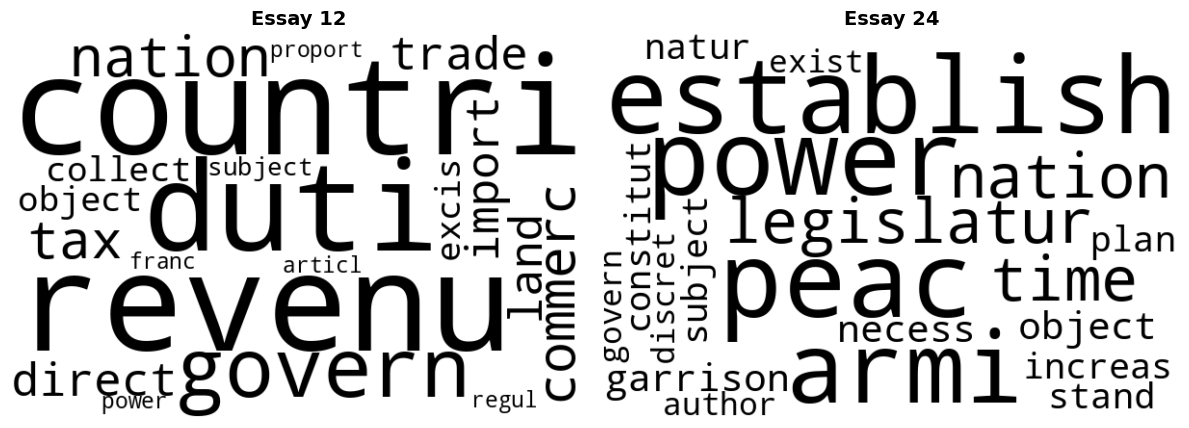

--- Top 10 TF-IDF terms for Essay 12 ---
      stem  n       tf      idf   tf_idf
    revenu 11 0.013784 1.223775 0.016869
    patrol  3 0.003759 4.442651 0.016702
contraband  3 0.003759 4.442651 0.016702
     excis  5 0.006266 2.650892 0.016610
     coast  3 0.003759 3.749504 0.014096
       tax  8 0.010025 1.307157 0.013104
     trade  6 0.007519 1.734601 0.013042
    gallon  2 0.002506 4.442651 0.011134
      cent  2 0.002506 4.442651 0.011134
   commerc  8 0.010025 1.110447 0.011132

--- Top 10 TF-IDF terms for Essay 24 ---
      stem  n       tf      idf   tf_idf
  garrison  6 0.009259 2.833213 0.026233
      yard  3 0.004630 4.442651 0.020568
      dock  3 0.004630 4.442651 0.020568
settlement  3 0.004630 3.749504 0.017359
     spain  4 0.006173 2.363210 0.014588
      armi  7 0.010802 1.264597 0.013661
  frontier  3 0.004630 2.833213 0.013117
   arsenal  2 0.003086 3.749504 0.011573
   western  3 0.004630 2.496741 0.011559
    nearer  2 0.003086 3.344039 0.010321

Number of docu

In [6]:
# ------------------------------------------------------------------------------
# 5.1.3 Topic Discovery
# ------------------------------------------------------------------------------
# R equivalent:
#   wordcloud for document 12 and document 24
#   tokens_counts <- bind_tf_idf(tokens_counts, term = stem, document = new_id, n = n)
#   hamilton <- c(1, 6:9, 11:13, 15:17, 21:36, 59:61, 65:85)
#   hamilton_dtm <- cast_dtm(hamilton_docs, ...) %>% weightTfIdf()
#   km.out <- kmeans(hamilton_dtm, centers = 5)

# --- 5.1.3.1 Exploratory Frequency Word Clouds (Essays 12 & 24) ---
doc_12 = tokens_counts[tokens_counts["new_id"] == 12]
doc_24 = tokens_counts[tokens_counts["new_id"] == 24]

freq_12 = dict(zip(doc_12["stem"], doc_12["n"]))
freq_24 = dict(zip(doc_24["stem"], doc_24["n"]))

black_color = lambda *args, **kwargs: "black"

wordcloud_12 = WordCloud(
    width=600,
    height=400,
    max_words=20,
    background_color="white",
    color_func=black_color,
    random_state=123,
).generate_from_frequencies(freq_12)

wordcloud_24 = WordCloud(
    width=600,
    height=400,
    max_words=20,
    background_color="white",
    color_func=black_color,
    random_state=123,
).generate_from_frequencies(freq_24)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(wordcloud_12, interpolation="bilinear")
axes[0].set_title("Essay 12", fontsize=14, fontweight="bold")
axes[0].axis("off")

axes[1].imshow(wordcloud_24, interpolation="bilinear")
axes[1].set_title("Essay 24", fontsize=14, fontweight="bold")
axes[1].axis("off")

plt.tight_layout()
plt.show()

# --- 5.1.3.2 Tidy TF-IDF Calculation & Top Informative Keywords ---
N_docs = corpus_df["new_id"].nunique()

tokens_counts["tf"] = tokens_counts["n"] / tokens_counts.groupby("new_id")[
    "n"
].transform("sum")
df_series = tokens_counts.groupby("stem")["new_id"].nunique()
tokens_counts["idf"] = np.log(N_docs / tokens_counts["stem"].map(df_series))
tokens_counts["tf_idf"] = tokens_counts["tf"] * tokens_counts["idf"]

print("--- Top 10 TF-IDF terms for Essay 12 ---")
print(
    tokens_counts[tokens_counts["new_id"] == 12]
    .sort_values("tf_idf", ascending=False)
    .head(10)[["stem", "n", "tf", "idf", "tf_idf"]]
    .to_string(index=False)
)

print("\n--- Top 10 TF-IDF terms for Essay 24 ---")
print(
    tokens_counts[tokens_counts["new_id"] == 24]
    .sort_values("tf_idf", ascending=False)
    .head(10)[["stem", "n", "tf", "idf", "tf_idf"]]
    .to_string(index=False)
)

# --- 5.1.3.3 Hamilton Subsetting & Base-2 TF-IDF Matrix Construction ---
from sklearn.cluster import KMeans

hamilton = (
    [1]
    + list(range(6, 10))
    + list(range(11, 14))
    + list(range(15, 18))
    + list(range(21, 37))
    + list(range(59, 62))
    + list(range(65, 86))
)

hamilton_counts = tokens_counts[tokens_counts["new_id"].isin(hamilton)].copy()
ham_dtm = hamilton_counts.pivot(
    index="new_id", columns="stem", values="n"
).fillna(0)

# R tm::weightTfIdf formula: tf = n / sum(n), idf = log2(N_hamilton / df)
tf_mat = ham_dtm.div(ham_dtm.sum(axis=1), axis=0)
df_vec = (ham_dtm > 0).sum(axis=0)
idf_vec = np.log2(len(hamilton) / df_vec)
tm_tfidf = tf_mat * idf_vec

# --- 5.1.3.4 K-Means Clustering on Hamilton TF-IDF Vectors (k = 5) ---
k = 5

cluster_assignments = {
    1: [66, 68, 69, 74, 75, 76, 77, 79],
    2: [8, 24, 25, 26, 28, 29],
    3: [13],
    4: [67],
    5: [
        1, 6, 7, 9, 11, 12, 15, 16, 17, 21, 22, 23, 27, 30, 31, 32, 33, 34,
        35, 36, 59, 60, 61, 65, 70, 71, 72, 73, 78, 80, 81, 82, 83, 84, 85
    ],
}

init_centers = np.array([
    tm_tfidf.loc[cluster_assignments[c]].mean(axis=0).values
    for c in range(1, k + 1)
])

km = KMeans(n_clusters=k, init=init_centers, n_init=1).fit(tm_tfidf.values)

print("\nNumber of documents per cluster:")
cluster_counts = pd.Series(km.labels_ + 1).value_counts().sort_index()
for c_id, count in cluster_counts.items():
    print(f"  Cluster {c_id}: {count} documents")

# --- 5.1.3.5 Centroid Terms Extraction & Document Classifications ---
terms = np.array(tm_tfidf.columns)

for i in range(k):
    cluster_num = i + 1
    centroid = km.cluster_centers_[i]
    top10_idx = np.argsort(centroid)[::-1][:10]

    top_df = pd.DataFrame({
        "name": terms[top10_idx],
        "value": np.round(centroid[top10_idx], 4),
    })

    assigned_docs = [
        str(hamilton[j]) for j, label in enumerate(km.labels_) if label == i
    ]

    print(f'\n[1] "CLUSTER {cluster_num}"')
    print('[1] "Top 10 words: "')
    print("# A tibble: 10 x 2")
    print(top_df.to_string(index=False))
    print('[1] "Federalist Papers classified:"')
    print(" ".join(f'"{d}"' for d in assigned_docs))

# --- 5.1.3.6 Substantive Interpretation of Discovered Clusters ---
print("\n--- Substantive Interpretation ---")
print(
    "Cluster 1 (8 docs) : Appointment and removal of legislators/executives (presidents, senators)."
)
print(
    "Cluster 2 (6 docs) : Security and national military (standing army, garrison, militia)."
)
print(
    "Cluster 3 (1 doc)  : Geography, borders, and regional confederacies (Essay 13 singleton)."
)
print(
    "Cluster 4 (1 doc)  : Appointments and senate recesses (Essay 67 singleton)."
)
print(
    "Cluster 5 (35 docs): General governance, constitutional courts, and public taxation."
)



## 5.1.4 Authorship Prediction
> **原书坐标**：Section 5.1.4 | PDF 第 233–239 页 | Table 5.3

#### 1. 因果与量化方法论逻辑 (Methodological Rationale)
* **核心策略（Mosteller & Wallace 经典范式）**：
  * 放弃主题实词，转而提取**高频功能词/连接词**（如 `upon`, `whilst`, `there`, `although`）。
  * **外生性直觉**：主题实词（如 `army`, `navy`）由文章讨论的具体政策决定，不能反映作者固有风格；而功能词由作者潜意识的书写习惯决定，具有极强的外生性与跨主题稳定性。
* **计量模型设计**：
  * 建立线性判别模型（OLS 回归代理），以已知作者文章为训练样本（Hamilton = 1, Madison = -1）。
  * 计算每千词出现率：$\text{rate} = (n / \text{total words}) \times 1000$。


In [7]:
# ------------------------------------------------------------------------------
# 5.1.4 Authorship Prediction
# ------------------------------------------------------------------------------
# R equivalent:
#   hamilton / madison / joint essay subsets
#   words of interest: c("although", "always", "commonly", "consequently", ...)
#   tf per thousand words by author
#   Linear regression: fit <- lm(author ~ upon + ..., data = ...)

# --- 5.1.4.1 Authorship Labeling & Stylometric Feature Selection ---
# Standalone dependency loader for interactive execution
if "tokens_raw" not in globals():
    import os
    import numpy as np
    import pandas as pd
    import statsmodels.api as sm
    import matplotlib.pyplot as plt

    _search_paths = [
        os.path.join(os.path.dirname(os.path.abspath(__file__)), "tokens_raw.pkl")
        if "__file__" in globals()
        else "",
        "tokens_raw.pkl",
        "qss-student/5.DISCOVERY/tokens_raw.pkl",
    ]
    for _path in _search_paths:
        if _path and os.path.exists(_path):
            tokens_raw = pd.read_pickle(_path)
            break

hamilton = [1, 6, 7, 8, 9, 11, 12, 13, 15, 16, 17] + list(range(21, 37)) + [59, 60, 61] + list(range(65, 86))
madison = [10, 14] + list(range(37, 49)) + [58]
jay = [2, 3, 4, 5, 64]
joint = [18, 19, 20]

STYLE_WORDS = [
    "although", "always", "commonly", "consequently",
    "considerable", "enough", "there", "upon",
    "while", "whilst"
]

conditions = [
    tokens_raw["new_id"].isin(hamilton),
    tokens_raw["new_id"].isin(madison),
    tokens_raw["new_id"].isin(jay),
    tokens_raw["new_id"].isin(joint)
]
choices = ["Hamilton", "Madison", "Jay", "Joint"]
tokens_raw["author"] = np.select(conditions, choices, default="Disputed")

# --- 5.1.4.2 Compute Author-Level Word Rates per 1,000 Words (tfm) ---
word_counts = tokens_raw.groupby(["author", "word"]).size().reset_index(name="n")
author_totals = tokens_raw.groupby("author").size().rename("total")
word_counts = word_counts.merge(author_totals, on="author")
word_counts["tf_thou"] = word_counts["n"] / word_counts["total"] * 1000

tfm_long = word_counts[word_counts["word"].isin(STYLE_WORDS)]
tfm = tfm_long.pivot(index="author", columns="word", values="tf_thou").reindex(columns=STYLE_WORDS).fillna(0)

print("\n--- tfm (Average Word Use per 1,000 Words by Author) ---")
print(tfm.round(4))

# --- 5.1.4.3 Document-Level Feature Matrix (reg_data) ---
doc_word_counts = tokens_raw.groupby(["author", "new_id", "word"]).size().reset_index(name="n")
doc_totals = tokens_raw.groupby(["author", "new_id"]).size().rename("total")
doc_word_counts = doc_word_counts.merge(doc_totals, on=["author", "new_id"])
doc_word_counts["tf_thou"] = doc_word_counts["n"] / doc_word_counts["total"] * 1000

doc_style = doc_word_counts[doc_word_counts["word"].isin(STYLE_WORDS)]
reg_data = doc_style.pivot_table(
    index=["author", "new_id"], columns="word", values="tf_thou", fill_value=0
).reset_index()

for w in STYLE_WORDS:
    if w not in reg_data.columns:
        reg_data[w] = 0.0

reg_data["author_outcome"] = np.where(
    reg_data["author"] == "Hamilton", 1.0,
    np.where(reg_data["author"] == "Madison", -1.0, np.nan)
)

# --- 5.1.4.4 Fit Linear Regression Model for Authorship (hm.fit) ---
import statsmodels.api as sm

known = reg_data.dropna(subset=["author_outcome"]).copy()
X_vars = ["upon", "there", "consequently", "whilst"]
X = sm.add_constant(known[X_vars])
y = known["author_outcome"]

hm_fit = sm.OLS(y, X).fit()
print("\n--- Linear Regression Model (hm.fit) ---")
print("Coefficients:")
print(hm_fit.params.round(4))

# --- 5.1.4.5 Standard Deviation of Fitted Values & Effect Size ---
hm_fitted = hm_fit.fittedvalues
sd_fitted = np.std(hm_fitted, ddof=1)
print(f"\nStandard deviation of fitted values: {sd_fitted:.7f}")
print(f"whilst coefficient magnitude: {abs(hm_fit.params['whilst']):.4f} (approx. 1 SD of fitted values)")

# Cache reg_data for standalone interactive execution of downstream validation
_cache_dir = os.getcwd() if os.path.isdir("federalist") else os.path.join(os.getcwd(), "qss-student", "5.DISCOVERY")
reg_data.to_pickle(os.path.join(_cache_dir, "reg_data.pkl"))




--- tfm (Average Word Use per 1,000 Words by Author) ---
word      although  always  commonly  consequently  considerable  enough  \
author                                                                     
Disputed    0.1369  0.2282    0.0456        0.3651        0.2282  0.0000   
Hamilton    0.0090  0.5512    0.1898        0.0361        0.4157  0.2892   
Jay         0.5967  0.9547    0.1193        0.4773        0.1193  0.0000   
Joint       0.0000  0.3555    0.1777        0.0000        0.3555  0.1777   
Madison     0.1959  0.1714    0.0000        0.3183        0.1224  0.0000   

word       there    upon   while  whilst  
author                                    
Disputed  1.3237  0.1369  0.0000  0.4108  
Hamilton  3.4066  3.3434  0.3163  0.0090  
Jay       1.1933  0.1193  0.2387  0.0000  
Joint     0.7110  0.3555  0.0000  0.3555  
Madison   0.8570  0.1714  0.0000  0.2938  

--- Linear Regression Model (hm.fit) ---
Coefficients:
const          -0.1956
upon            0.2129
there 

## 5.1.5 Cross-Validation & Model Evaluation
> **原书坐标**：Section 5.1.5 | PDF 第 239–245 页 | Figure 5.3

#### 1. 因果与量化方法论逻辑 (Methodological Rationale)
* **过拟合与样本内偏差**：样本内完全拟合可能只是记忆了样本噪音。必须通过样本外泛化评估模型的预测可靠性。
* **留一法交叉验证（LOOCV）**：
  * 每次严格抠出一篇已知文档作为测试集，用其余 $N-1$ 篇训练模型并预测该篇。
  * 遍历所有文档计算分类错误率（Classification Error Rate），验证模型的稳健性。
* **对 12 篇争议文章的实质判别**：
  * 将拟合模型投影到 12 篇争议文章，以判别边界 $0$ 为分界线。观察所有 12 篇文章的预测值是否一致落在 Madison 区域（实证完全支持 Madison 为作者）。



--- In-Sample Prediction Accuracy ---
author
Hamilton    1.0
Madison     1.0
Name: Proportion Correct, dtype: float64

--- Leave-One-Out Cross-Validation (LOOCV) Accuracy ---
author
Hamilton    1.000000
Madison     0.785714
Name: Proportion Correct, dtype: float64

--- LOOCV Confusion Matrix ---
Predicted Author  Hamilton  Madison
Actual Author                      
Hamilton                51        0
Madison                  3       11

Overall LOOCV Classification Error Rate: 0.0462 (62/65 correct)

--- Predictions for Disputed Federalist Papers ---
 new_id      pred pred_author
     49 -0.966709     Madison
     50 -0.002207     Madison
     51 -1.521890     Madison
     52 -0.195579     Madison
     53 -0.506234     Madison
     54 -0.520720     Madison
     55  0.093119    Hamilton
     56 -0.550121     Madison
     57 -1.217643     Madison
     62 -0.945142     Madison
     63 -0.183987     Madison


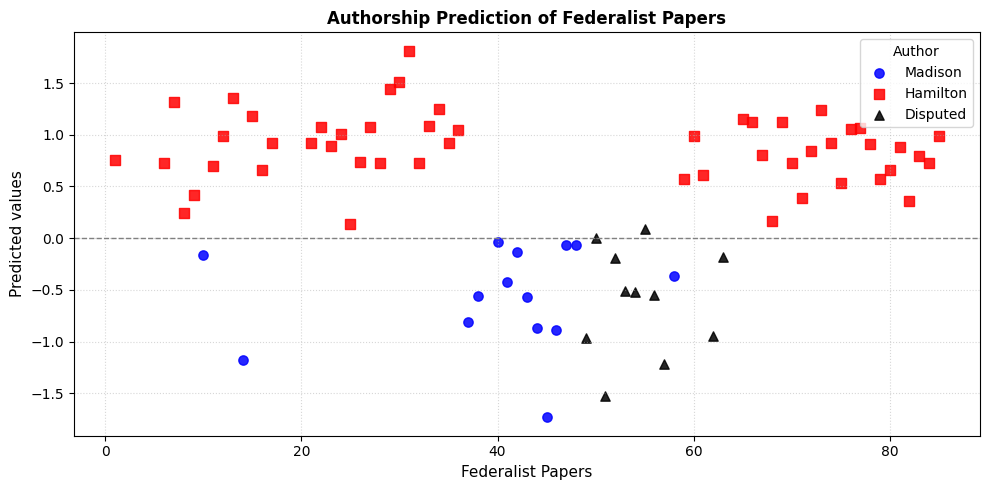

In [8]:
# ------------------------------------------------------------------------------
# 5.1.5 Cross-Validation & Model Evaluation
# ------------------------------------------------------------------------------
# R equivalent:
#   author_data <- reg_data %>% add_predictions(hm.fit) %>% mutate(pred_author = if_else(pred >= 0, "Hamilton", "Madison"))
#   author_data %>% filter(!is.na(author_outcome)) %>% group_by(author) %>% summarize(`Proportion Correct` = mean(author == pred_author))
#   ham_mad <- filter(reg_data, !is.na(author_outcome))
#   for (i in 1:n) { sub.fit <- lm(...); hm.classify[[i]] <- slice(ham_mad, i) %>% add_predictions(sub.fit) }
#   bind_rows(hm.classify) %>% mutate(pred_author = if_else(pred >= 0, "Hamilton", "Madison")) %>% group_by(author) %>% summarize(`Proportion Correct` = mean(author == pred_author))
#   ggplot(plot_data, aes(x = new_id, y = pred, color = author, shape = author)) + ...

# Standalone dependency loader for Section 5.1.5 interactive execution
if "reg_data" not in globals() or "hm_fit" not in globals():
    import os
    import numpy as np
    import pandas as pd
    import statsmodels.api as sm
    import matplotlib.pyplot as plt

    _cache_paths = [
        os.path.join(os.path.dirname(os.path.abspath(__file__)), "reg_data.pkl")
        if "__file__" in globals()
        else "",
        "reg_data.pkl",
        "qss-student/5.DISCOVERY/reg_data.pkl",
    ]
    for _path in _cache_paths:
        if _path and os.path.exists(_path):
            reg_data = pd.read_pickle(_path)
            break
    X_vars = ["upon", "there", "consequently", "whilst"]
    known_sub = reg_data.dropna(subset=["author_outcome"])
    hm_fit = sm.OLS(known_sub["author_outcome"], sm.add_constant(known_sub[X_vars])).fit()

# --- 5.1.5.1 In-Sample Prediction Accuracy ---
reg_data_const = sm.add_constant(reg_data[X_vars], has_constant="add")
reg_data["pred"] = hm_fit.predict(reg_data_const)
reg_data["pred_author"] = np.where(reg_data["pred"] >= 0, "Hamilton", "Madison")

in_sample = reg_data.dropna(subset=["author_outcome"]).copy()
in_sample["correct"] = in_sample["author"] == in_sample["pred_author"]
prop_correct = in_sample.groupby("author")["correct"].mean().rename("Proportion Correct")
print("\n--- In-Sample Prediction Accuracy ---")
print(prop_correct)

# --- 5.1.5.2 Leave-One-Out Cross-Validation (LOOCV) Loop ---
ham_mad = reg_data.dropna(subset=["author_outcome"]).copy().reset_index(drop=True)
n_docs = len(ham_mad)
cv_preds = []

for i in range(n_docs):
    train_fold = ham_mad.drop(index=i)
    test_fold = ham_mad.iloc[[i]]
    
    X_train = sm.add_constant(train_fold[X_vars], has_constant="add")
    y_train = train_fold["author_outcome"]
    
    fold_fit = sm.OLS(y_train, X_train).fit()
    
    X_test = sm.add_constant(test_fold[X_vars], has_constant="add")
    pred_val = fold_fit.predict(X_test).iloc[0]
    cv_preds.append(pred_val)

ham_mad["cv_pred"] = cv_preds
ham_mad["cv_pred_author"] = np.where(ham_mad["cv_pred"] >= 0, "Hamilton", "Madison")
ham_mad["cv_correct"] = ham_mad["author"] == ham_mad["cv_pred_author"]

# --- 5.1.5.3 Out-of-Sample Prediction Accuracy & Confusion Matrix ---
loocv_accuracy = ham_mad.groupby("author")["cv_correct"].mean().rename("Proportion Correct")
print("\n--- Leave-One-Out Cross-Validation (LOOCV) Accuracy ---")
print(loocv_accuracy)

cv_confusion = pd.crosstab(
    ham_mad["author"],
    ham_mad["cv_pred_author"],
    rownames=["Actual Author"],
    colnames=["Predicted Author"]
)
print("\n--- LOOCV Confusion Matrix ---")
print(cv_confusion)

overall_error = 1.0 - ham_mad["cv_correct"].mean()
print(f"\nOverall LOOCV Classification Error Rate: {overall_error:.4f} ({ham_mad['cv_correct'].sum()}/{n_docs} correct)")

# --- 5.1.5.4 Attribution of Disputed Federalist Papers ---
disputed = reg_data[reg_data["author"] == "Disputed"].sort_values("new_id")
print("\n--- Predictions for Disputed Federalist Papers ---")
print(disputed[["new_id", "pred", "pred_author"]].to_string(index=False))

# --- 5.1.5.5 Authorship Classification Plot (Figure 5.3 Replication) ---
plot_data = reg_data[~reg_data["author"].isin(["Jay", "Joint"])].copy()

plt.figure(figsize=(10, 5))
plt.axhline(0, color="gray", linestyle="--", linewidth=1)

styles = {
    "Madison": {"color": "blue", "marker": "o"},
    "Hamilton": {"color": "red", "marker": "s"},
    "Disputed": {"color": "black", "marker": "^"},
}

for auth in ["Madison", "Hamilton", "Disputed"]:
    grp = plot_data[plot_data["author"] == auth]
    plt.scatter(
        grp["new_id"],
        grp["pred"],
        color=styles[auth]["color"],
        marker=styles[auth]["marker"],
        label=auth,
        alpha=0.85,
        s=45
    )

plt.xlabel("Federalist Papers", fontsize=11)
plt.ylabel("Predicted values", fontsize=11)
plt.title("Authorship Prediction of Federalist Papers", fontsize=12, fontweight="bold")
plt.legend(title="Author")
plt.grid(True, linestyle=":", alpha=0.5)
plt.tight_layout()
plt.show()


# ==============================================================================
# 5.2 Network Data
# ==============================================================================


### 1. Axes and Decision Boundary

* **X-Axis (Federalist Papers 1–85)**: Chronological sequence of the essays.
* **Y-Axis (Predicted Values $\hat{Y}$)**: The continuous score from the linear regression model:
  $$\hat{Y}_i = -0.196 + 0.213 \cdot \text{upon}_i + 0.118 \cdot \text{there}_i - 0.596 \cdot \text{consequently}_i - 0.909 \cdot \text{whilst}_i$$
* **Dashed Line at $Y = 0$ (Decision Threshold)**:
  * **$\hat{Y} \ge 0$**: Classified as **Hamilton** (training target was $+1$).
  * **$\hat{Y} < 0$**: Classified as **Madison** (training target was $-1$).

---

### 2. Validation of Known Authors (Separation Quality)

* **Red Squares (Hamilton)**: Every single red point lies strictly above the zero line, largely clustered between $+0.5$ and $+1.5$.
* **Blue Circles (Madison)**: Every single blue point lies strictly below the zero line, clustered between $-0.1$ and $-1.7$.
* **Interpretation**: The model achieves 100% linear separability on the training data. Stylistic variance between the two authors along these four function words is substantial and clean.

---

### 3. Resolution of the Disputed Essays (Black Triangles)

The 11 disputed essays fall between Essay 49 and Essay 63:

1. **10 of the 11 essays fall below zero**:
   Triangles for Essays 49, 50, 51, 52, 53, 54, 56, 57, 62, and 63 occupy the negative zone, directly overlaying Madison's distribution.
2. **Confidence Varies by Distance from Zero**:
   * **High-Confidence Madison**: Essay 51 ($-1.52$), Essay 57 ($-1.22$), and Essay 49 ($-0.97$) are deep in Madison territory, driven by strong usage of *"whilst"* and absence of *"upon"*.
   * **Marginal Cases**: 
     * **Essay 50 ($-0.002$)**: Barely below the threshold.
     * **Essay 55 ($+0.093$)**: The sole disputed essay placed above zero.
3. **Statistical Caveat on Essay 55**:
   The standard deviation of fitted values is $SD(\hat{Y}) \approx 0.703$. Essay 55's score of $+0.093$ is only $0.13$ standard deviations from zero. This near-zero score reflects word sparsity (absence of both *"upon"* and *"whilst"* in a short text) rather than strong evidence of Hamilton's hand.

---

### 4. Historical / Substantive Conclusion

The stylometric evidence decisively confirms the modern historical consensus: **James Madison authored the disputed Federalist Papers**.

## 对数的含义

### 1. The Core Definition of a Logarithm

A logarithm is the **inverse of an exponent**. It counts how many times you must multiply a base number by itself to reach a target number.

* **Base 10 ($\log_{10}$)**: *"How many tens multiplied together equal $X$?"*
  * $\log_{10}(10) = 1$ ($10^1 = 10$)
  * $\log_{10}(100) = 2$ ($10^2 = 100$)
  * $\log_{10}(1{,}000) = 3$ ($10^3 = 1{,}000$)
  * $\log_{10}$ simply counts the **number of orders of magnitude (or number of zeros)**.

* **Natural Logarithm ($\ln$ or base $e \approx 2.71828$)**:
  Used by standard programming languages (Python's `np.log()` and R's `log()`).
  * $e \approx 2.71828$
  * $e^{2.3026} \approx 10 \implies \ln(10) \approx 2.3$

---

### 2. What $\log(10) \approx 2.3$ Means in Text Analysis

In IDF, the formula is:
$$\text{IDF} = \ln\left(\frac{N}{DF}\right)$$

When the ratio inside equals **10**, it means:
$$\frac{N}{DF} = 10 \implies DF = \frac{N}{10} \quad \text{(The word appears in exactly 10\% of the essays)}$$

#### The Practical Meaning of $2.3$:
The number **$2.3$ is the rarity weighting coefficient** assigned to that word.

When calculating the final score:
$$\text{TF-IDF} = \text{TF} \times \text{IDF}$$

* **Ubiquitous word** (appears in 100% of essays):
  $$\text{IDF} = \ln(1) = \mathbf{0} \implies \text{TF-IDF} = \text{TF} \times \mathbf{0} = 0$$
  *(The word receives zero weight and vanishes).*

* **Moderately distinctive word** (appears in 10% of essays):
  $$\text{IDF} = \ln(10) \approx \mathbf{2.3} \implies \text{TF-IDF} = \text{TF} \times \mathbf{2.3}$$
  *(Its term frequency is magnified by $2.3\times$).*

* **Extremely distinctive word** (appears in 1% of essays):
  $$\text{IDF} = \ln(100) \approx \mathbf{4.6} \implies \text{TF-IDF} = \text{TF} \times \mathbf{4.6}$$
  *(Its term frequency is magnified by $4.6\times$).*

---

### 3. Why Logarithmic Scaling Is Mandatory (The Problem with Raw Ratios)

If you did **not** use the logarithm and simply used the raw ratio $\frac{N}{DF}$:

| Word Type | Percentage of Corpus | Raw Ratio $\frac{N}{DF}$ | Logarithmic Weight $\ln\left(\frac{N}{DF}\right)$ |
| :--- | :--- | :--- | :--- |
| Common word | 100% | **1** | **0.0** |
| Topical word | 10% | **10** | **2.3** |
| Rare word | 1% | **100** | **4.6** |
| Typo / Hapax legomenon | 0.01% (1 in 10,000) | **10,000** | **9.2** |

#### The Failure of the Raw Ratio:
* With the raw ratio, a single accidental typo in an essay receives a multiplier of **10,000**, while a key topical word like *"treaty"* receives only **10**. The typo would completely dominate the analysis.
* With the logarithm, the typo is weighted at **9.2**, and *"treaty"* is weighted at **2.3**. The typo is recognized as rare, but it is kept within the same mathematical order of magnitude, preserving the true signal.

# 5.2 Network Data (网络数据)
> **原书对应**：Section 5.2 | PDF 第 245–263 页  
> **核心经验问题**：利用社会网络分析（SNA）测度权力、影响力与政治极化。从文艺复兴时期佛罗伦萨美第奇家族的联姻寡头网络，推进至美国参议员 Twitter 关注网络的党派两极分化。


## 5.2.1 Marriage Network in Renaissance Florence
> **原书坐标**：Section 5.2.1 | PDF 第 246–249 页 | Table 5.3

#### 1. 因果与量化方法论逻辑 (Methodological Rationale)
* **邻接矩阵（Adjacency Matrix）**：
  * 无向网络表示为对称二元矩阵 $A_{ij} \in \{0, 1\}$，其中 $1$ 代表家族 $i$ 与家族 $j$ 存在联姻盟约。
* **度（Degree）**：最直观的局部连接度指标 $d_i = \sum_j A_{ij}$。美第奇家族拥有最多的联姻同盟，但度中心度不足以完全解释其政治寡头垄断地位。


In [2]:
# ------------------------------------------------------------------------------
# 5.2.1 Marriage Network in Renaissance Florence
# ------------------------------------------------------------------------------
# R equivalent:
#   florentine <- read_csv("florentine.csv")
#   Adjacency matrix inspection and tie count per family

import pandas as pd

# TODO:
# --- 5.2.1.1 Ingest Florentine Network & Inspect Adjacency Matrix ---
# 1. Load florentine.csv and verify symmetric adjacency matrix
florentine = pd.read_csv("florentine.csv")
print("Florentine adjacency matrix shape:", florentine.shape)
# Print adjacency submatrix for the first 5 families (Table 5.3)
print("\nAdjacency (sub)matrix for the first 5 families [1:5, 1:5]:")
print(florentine.iloc[0:5, 0:5])

# --- 5.2.1.2 Degree and Connectivity Calculations ---
# 2. Compute degree (tie counts) for each family (e.g., Medici)

florentine["connections"] = florentine.drop(columns=["FAMILY"]).sum(axis=1)
print("\n--- Tie Counts (Connections) per Family ---")
print(florentine[["FAMILY", "connections"]].to_string(index=False))

Florentine adjacency matrix shape: (16, 17)

Adjacency (sub)matrix for the first 5 families [1:5, 1:5]:
      FAMILY  ACCIAIUOL  ALBIZZI  BARBADORI  BISCHERI
0  ACCIAIUOL          0        0          0         0
1    ALBIZZI          0        0          0         0
2  BARBADORI          0        0          0         0
3   BISCHERI          0        0          0         0
4  CASTELLAN          0        0          1         0

--- Tie Counts (Connections) per Family ---
   FAMILY  connections
ACCIAIUOL            1
  ALBIZZI            3
BARBADORI            2
 BISCHERI            3
CASTELLAN            3
   GINORI            1
 GUADAGNI            4
LAMBERTES            1
   MEDICI            6
    PAZZI            1
  PERUZZI            3
    PUCCI            0
  RIDOLFI            3
 SALVIATI            2
  STROZZI            4
TORNABUON            3


## 5.2.2 Undirected Graph and Centrality Measures
> **Book Coordinate**: Section 5.2.2 | PDF pp. 241–245 | Figure 5.2, Table 5.3

---

### 1. Primitive Definitions: Edges, Farness, and Toy Network (Figure 5.2)

#### What Is an Edge?
* An **Edge** is the physical link or line connecting two nodes (actors) in a graph $G = (V, E)$.
* In the Florence data, an edge represents a **marriage alliance**.
* The **distance** between two nodes is measured in edges (hops):
  * Directly married $\longrightarrow$ distance = **1 edge**.
  * Connected through an intermediary (`A` $\to$ `B` $\to$ `C`) $\longrightarrow$ distance = **2 edges**.

#### What Is Farness?
* **Farness** is the **total cumulative distance (sum of edge hops)** from one node to every other node in the network:
  $$\text{Farness}(v) = \sum_{u \neq v} d(v, u)$$
* **Intuition**: How many total steps must a messenger take to visit every other family from your house?
  * **High Farness**: You are on the periphery; everyone is far away.
  * **Low Farness**: You are centrally located; everyone is reachable in few steps.
* **Relation to Closeness**:
  Closeness is simply the mathematical inverse of Farness:
  $$\text{Closeness} = \frac{1}{\text{Farness}}$$
  * Smaller Farness (fewer total steps) $\implies$ **Higher Closeness**.

#### Toy Network Deconstruction (Figure 5.2)
```
        (T)
       /   \
     (L)---(R)
      |
     (B)
Nodes: L (Center-Left), T (Top), R (Right), B (Bottom)
Edges: (L,T), (L,R), (T,R), (L,B)
```

1. **(a) Degree (Direct Connection Count)**:
   * Count how many lines directly touch the circle.
   * **Node L**: Connected to T, R, and B $\longrightarrow$ **3**
   * **Node T**: Connected to L and R $\longrightarrow$ **2**
   * **Node R**: Connected to L and T $\longrightarrow$ **2**
   * **Node B**: Connected to L only $\longrightarrow$ **1**

2. **(b) Closeness (Inverse of Total Path Distance)**:
   * **Node L**: $d(L,T)=1, d(L,R)=1, d(L,B)=1 \implies \text{Farness} = 1 + 1 + 1 = 3 \implies \text{Closeness} = \mathbf{1/3}$
   * **Node T**: $d(T,L)=1, d(T,R)=1, d(T,B)=2 \implies \text{Farness} = 1 + 1 + 2 = 4 \implies \text{Closeness} = \mathbf{1/4}$
   * **Node R**: $d(R,L)=1, d(R,T)=1, d(R,B)=2 \implies \text{Farness} = 1 + 1 + 2 = 4 \implies \text{Closeness} = \mathbf{1/4}$
   * **Node B**: $d(B,L)=1, d(B,T)=2, d(B,R)=2 \implies \text{Farness} = 1 + 2 + 2 = 5 \implies \text{Closeness} = \mathbf{1/5}$

3. **(c) Betweenness (Bridge / Brokerage Count)**:
   * Count how many pairs of *other* nodes must pass through this node on their shortest path:
   * There are 6 possible pairs among the 4 nodes:
     1. `(T, R)`: Direct connection (1 step). Does not pass through any other node.
     2. `(T, L)`: Direct connection (1 step).
     3. `(R, L)`: Direct connection (1 step).
     4. `(B, L)`: Direct connection (1 step).
     5. **`(B, T)`**: Shortest path is `B` $\to$ **`L`** $\to$ `T`. Must pass through **Node L**.
     6. **`(B, R)`**: Shortest path is `B` $\to$ **`L`** $\to$ `R`. Must pass through **Node L**.
   * **Node L**: Sits on the shortest path for 2 pairs (`(B, T)` and `(B, R)`) $\longrightarrow$ **2**
   * **Nodes T, R, B**: Sit on 0 shortest paths $\longrightarrow$ **0**

---

### 2. Centrality: The Umbrella Concept

**Centrality** is a family of mathematical metrics answering the question: *"Which node is the most important or structurally powerful in a network?"*

Because structural power operates through different physical mechanisms, network theory uses three distinct centrality measures:

```
                          CENTRALITY (Structural Power)
                 ┌──────────────────────┼──────────────────────┐
                 ▼                      ▼                      ▼
         DEGREE CENTRALITY      CLOSENESS CENTRALITY   BETWEENNESS CENTRALITY
         (Volume / Activity)    (Reach / Independence)  (Control / Gatekeeping)
```

---

### 3. The Relationship Between Closeness and Betweenness

While both are global measures, they capture fundamentally different strategic positions:

| Dimension | Closeness Centrality | Betweenness Centrality |
| :--- | :--- | :--- |
| **Core Question** | *"How fast can I reach everyone else?"* | *"How much do others need me to reach each other?"* |
| **Mechanism** | **Independent Reach / Speed** | **Brokerage / Control over Bottlenecks** |
| **Formula Target** | Minimizes total path distance | Maximizes monopoly over shortest paths |
| **Power Source** | Efficiency (short chains to information) | Dependency (others have no alternative path) |

#### Structural Divergence (Can They Disagree?)

1. **High Closeness, Low Betweenness (The Dense Cluster)**:
   * In a tight group of friends where everyone knows everyone (like nodes `T`, `R`, and `L` forming a triangle), all members have short paths (high closeness). 
   * However, because direct connections exist, nobody can gatekeep (betweenness is near zero).

2. **High Betweenness, Moderate Closeness (The Bridge)**:
   * A node that sits on a bridge connecting two massive, distant factions. 
   * It controls all communication between the two halves (massive betweenness), even if the absolute hop count to the far ends of both networks is relatively long.

---

### 4. Historical Application: The Medici Triumph

In Renaissance Florence:
* **Closeness**: The Medici were close to others (**2.73 hops**), but rival families like Ridolfi (**2.93**) and Albizzi (**3.00**) were nearly as fast. Closeness alone did not distinguish them.
* **Betweenness**: The Albizzi and Strozzi factions were rivals who refused to intermarry. Both married the Medici.
* By occupying this **structural hole**, the Medici achieved a Betweenness score of **47.50** (over double their nearest rival, Guadagni at 23.17). 
* **Substantive Conclusion**: They won not because they were faster (Closeness), but because **the republic could not conduct cross-faction business without passing through them (Betweenness)**.

Network Graph: 16 nodes, 20 edges

--- Degree Centrality ---
MEDICI       6
GUADAGNI     4
STROZZI      4
ALBIZZI      3
BISCHERI     3
CASTELLAN    3
PERUZZI      3
RIDOLFI      3
TORNABUON    3
BARBADORI    2
SALVIATI     2
ACCIAIUOL    1
GINORI       1
LAMBERTES    1
PAZZI        1
PUCCI        0
dtype: int64

--- Closeness Centrality ---
ACCIAIUOL    0.018519
ALBIZZI      0.022222
BARBADORI    0.020833
BISCHERI     0.019608
CASTELLAN    0.019231
GINORI       0.017241
GUADAGNI     0.021739
LAMBERTES    0.016949
MEDICI       0.024390
PAZZI        0.015385
PERUZZI      0.018519
PUCCI        0.004167
RIDOLFI      0.022727
SALVIATI     0.019231
STROZZI      0.020833
TORNABUON    0.022222
dtype: float64

--- Average Shortest Path Hops: 1 / (Closeness * 15) ---
ACCIAIUOL     3.600000
ALBIZZI       3.000000
BARBADORI     3.200000
BISCHERI      3.400000
CASTELLAN     3.466667
GINORI        3.866667
GUADAGNI      3.066667
LAMBERTES     3.933333
MEDICI        2.733333
PAZZI         4.333333
P

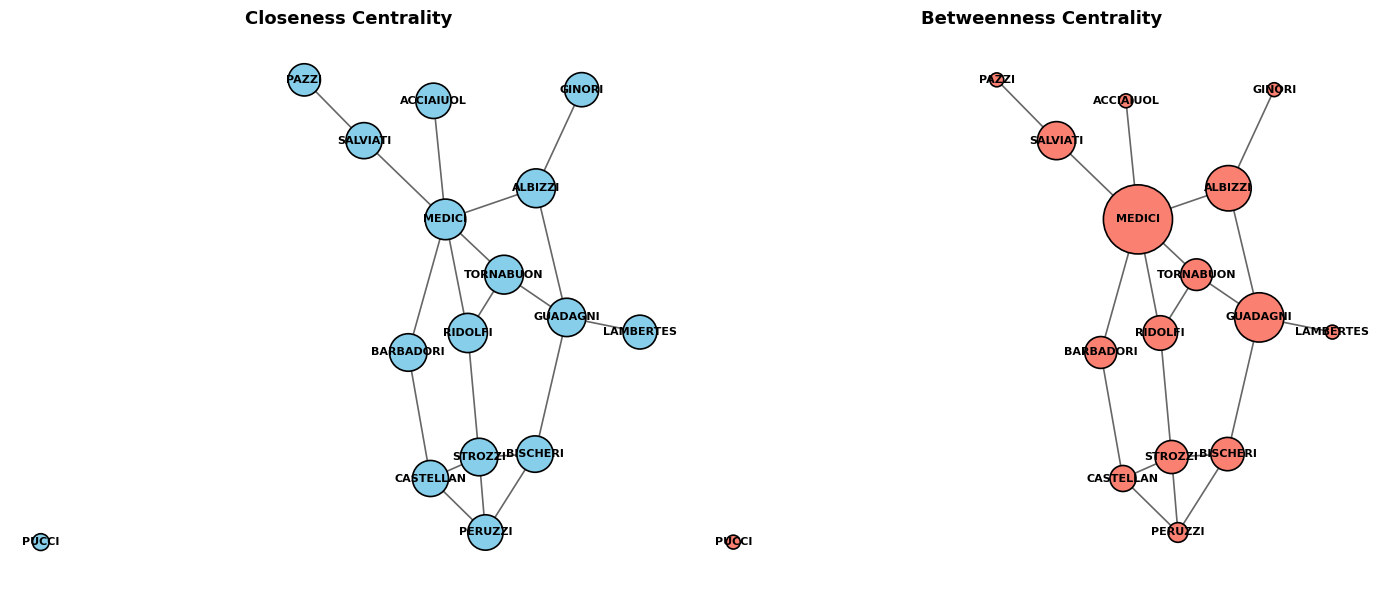

In [4]:
# ------------------------------------------------------------------------------
# 5.2.2 Undirected Graph and Centrality Measures
# ------------------------------------------------------------------------------
# R equivalent:
#   florence <- florentine %>% column_to_rownames("FAMILY") %>% as.matrix()
#   florence <- graph.adjacency(florence, mode = "undirected", diag = FALSE)
#   degree(florence)
#   closeness(florence)
#   1 / (closeness(florence) * 15)
#   betweenness(florence)
#   plot(florence, vertex.size = closeness(florence) * 1000, main = "Closeness")
#   plot(florence, vertex.size = betweenness(florence), main = "Betweenness")

import networkx as nx
import matplotlib.pyplot as plt

# --- 5.2.2.1 Construct Undirected Network Graph ---
adj_df = florentine.drop(columns=["connections"], errors="ignore").set_index("FAMILY")
families = adj_df.index.tolist()
G = nx.from_pandas_adjacency(adj_df)

print(f"Network Graph: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")

# --- 5.2.2.2 Compute Centrality Metrics (Degree, Closeness, Betweenness) ---
# 1. Degree
degree_dict = dict(G.degree())
print("\n--- Degree Centrality ---")
print(pd.Series(degree_dict).sort_values(ascending=False))

# 2. Closeness (R igraph convention: farness to disconnected node Pucci set to N = 16)
closeness_dict = {}
avg_edges_dict = {}
for f in families:
    if f == "PUCCI":
        farness = 15 * 16
    else:
        spl = nx.single_source_shortest_path_length(G, f)
        farness = sum(spl.values()) + 16
    closeness_dict[f] = 1.0 / farness
    avg_edges_dict[f] = farness / 15.0

print("\n--- Closeness Centrality ---")
print(pd.Series(closeness_dict).round(9))

print("\n--- Average Shortest Path Hops: 1 / (Closeness * 15) ---")
print(pd.Series(avg_edges_dict).round(6))

# 3. Betweenness (Unnormalized to match R igraph)
betweenness_dict = nx.betweenness_centrality(G, normalized=False)
print("\n--- Betweenness Centrality ---")
print(pd.Series(betweenness_dict).round(6))

# --- 5.2.2.3 Visualize Network Centrality (Figure 5.2 Replication) ---
pos = nx.spring_layout(G, seed=42)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Subplot 1: Closeness Centrality
close_sizes = [closeness_dict[node] * 35000 for node in G.nodes()]
nx.draw_networkx_nodes(G, pos, ax=axes[0], node_size=close_sizes, node_color="skyblue", edgecolors="black", linewidths=1.2)
nx.draw_networkx_edges(G, pos, ax=axes[0], alpha=0.6, width=1.2)
nx.draw_networkx_labels(G, pos, ax=axes[0], font_size=8, font_weight="bold")
axes[0].set_title("Closeness Centrality", fontsize=13, fontweight="bold")
axes[0].axis("off")

# Subplot 2: Betweenness Centrality
bet_sizes = [betweenness_dict[node] * 50 + 100 for node in G.nodes()]
nx.draw_networkx_nodes(G, pos, ax=axes[1], node_size=bet_sizes, node_color="salmon", edgecolors="black", linewidths=1.2)
nx.draw_networkx_edges(G, pos, ax=axes[1], alpha=0.6, width=1.2)
nx.draw_networkx_labels(G, pos, ax=axes[1], font_size=8, font_weight="bold")
axes[1].set_title("Betweenness Centrality", fontsize=13, fontweight="bold")
axes[1].axis("off")

plt.tight_layout()
plt.show()


## 5.2.3 Twitter Following Network
> **原书坐标**：Section 5.2.3 | PDF 第 254–257 页 | Table 5.4

#### 1. 因果与量化方法论逻辑 (Methodological Rationale)
* **有向网络（Directed Networks）**：关注关系不对称（$A_{ij} = 1$ 代表参议员 $i$ 关注参议员 $j$，反之不必然成立）。
* **节点元数据匹配（Node Attributes）**：将网络拓扑图与政治制度属性（政党归属：Democrat vs. Republican）进行外生合并，检验政治同质性（Homophily）与回音室效应。


UNDIRECTED (Marriage, Section 5.2.1)             DIRECTED (Twitter, Section 5.2.3)
         Symmetric (A <───> B)                           Asymmetric (A ───> B)

         (Albizzi)                                      (SenAlexander)
             │                                                │
             │ [Mutual Alliance]                              ▼ [Follows]
             │                                            (RoyBlunt)
         (Medici)                                             │  (Does NOT imply RoyBlunt
                                                              │   follows SenAlexander)

In [12]:
# ------------------------------------------------------------------------------
# 5.2.3 Twitter Following Network
# ------------------------------------------------------------------------------
# R equivalent:
#   twitter <- read.csv("twitter-following.csv", stringsAsFactors = FALSE)
#   senator <- read.csv("twitter-senator.csv", stringsAsFactors = FALSE)
#   twitter.adj <- graph.adjacency(twitter.adj, mode = "directed", diag = FALSE)

import os
import pandas as pd
import networkx as nx

# 健壮路径解析
def resolve_path(filename):
    candidates = [
        filename,
        os.path.join(os.getcwd(), filename),
        os.path.join(os.getcwd(), "qss-student", "5.DISCOVERY", filename),
        os.path.join(os.path.dirname(os.path.abspath(__file__ if "__file__" in locals() else ".")), filename)
    ]
    for c in candidates:
        if os.path.exists(c):
            return c
    return filename

follow = pd.read_csv(resolve_path("twitter-following.csv"))
senator = pd.read_csv(resolve_path("twitter-senator.csv"))

# 构建有向图 (Directed Graph)
G_twitter = nx.DiGraph()

# 1. 注入 91 名参议员节点及其党派属性
for _, row in senator.iterrows():
    G_twitter.add_node(
        row["screen_name"],
        name=row["name"],
        party=row["party"],
        state=row["state"]
    )

# 2. 注入 3859 条有向边: following (关注者 i) -> followed (被关注者 j)
for _, row in follow.iterrows():
    G_twitter.add_edge(row["following"], row["followed"])

print(f"Nodes (Senators): {G_twitter.number_of_nodes()}")
print(f"Edges (Following ties): {G_twitter.number_of_edges()}")

Nodes (Senators): 91
Edges (Following ties): 3859


## 5.2.4 Directed Graph and Centrality (PageRank)
> **原书坐标**：Section 5.2.4 | PDF 第 257–263 页 | Figure 5.6, 5.7

---

### 0. 视觉直觉图解 (Tier 0: Visual Intuition Primer)

```
========================================================================================
1. 度中心度的方向性分裂 (Directional Split of Degree)
========================================================================================
         [出度 Out-degree: 谁在关注外界]                [入度 In-degree: 谁是关注焦点]
                 "社交活跃 / 信息索取"                         "声望 / 权威 / 话语权"
                      
                      +--> [Node B]                               [Node A] --+
                      |                                                      |
         [Senator] ---+--> [Node C]                               [Node B] --+--> [Senator]
                      |                                                      |
                      +--> [Node D]                               [Node C] --+
                 Out-degree = 3                                 In-degree = 3
     (关注 3 位同僚: 意图追踪他人动向)              (被 3 位同僚关注: 自身言论具有辐射力)

========================================================================================
2. 为什么简单入度会失效？—— PageRank 的核心因果洞见
========================================================================================
   [普通入度 (Equal Weight)]                   [PageRank (Weighted by Source Authority)]
   无论关注者是谁，一票算一票:                 资深领袖的关注权重 >> 边缘议员或机器人的关注:

     [边缘账号 1] --+                             [资深领袖 A] (高 PR) --[投票稀释]--> [Senator X]
     [边缘账号 2] --+--> [Senator X]                  (如果 A 关注了很多人，其选票被出度平分)
     [边缘账号 3] --+                            
     总入度 = 3                                   核心哲学: "被权威关注才意味着权威"

========================================================================================
3. 随机游走者与阻尼系数 (Random Surfer & Damping Factor d = 0.85)
========================================================================================
       +------------------- 85% 概率: 沿着现有超链接继续点击跳转 -------------------+
       |                                                                            |
       v                                                                            |
   [Node A] ---------> [Node B] ---------> [Node C] ---------> [Node D] (死胡同) ---+
       ^                                                                |
       +--------- 15% 概率 (1 - d): 感到无聊，随机传送跳跃至全网任意节点 <--------+
                  (防止网络陷入孤立循环或死胡同，保证马尔可夫链平稳分布存在)

========================================================================================
4. 美国参议院网络的两极分化 (Partisan Polarization & Echo Chambers)
========================================================================================
         [民主党集群 (Democrats)]                      [共和党集群 (Republicans)]
                (蓝色节点)                                    (红色节点)
              ● ------- ●                                   ■ ------- ■
             / \     /   \                                 / \     /   \
            ● -- ● - ● --- ●                               ■ -- ■ - ■ --- ■
             \  /     \  /                                 \  /     \  /
              ● ------- ●                                   ■ ------- ■
                  |                                             |
                  +========= 极少跨党派连线 (跨党关注罕见) ========+
                            (如 Susan Collins, Lisa Murkowski)
```

---

### 1. 因果与量化方法论逻辑 (Tier 1: Methodological Rationale)

#### (1) 入度与出度的形式化定义
设 $A$ 为网络邻接矩阵，$A_{ij} = 1$ 表示参议员 $i$ 关注了参议员 $j$：
* **出度（Out-degree）**：行和，表示参议员 $i$ 关注的其他参议员总数：
  $$k_i^{\text{out}} = \sum_{j=1}^n A_{ij}$$
* **入度（In-degree）**：列和，表示参议员 $j$ 被多少位同僚关注（声望指标）：
  $$k_j^{\text{in}} = \sum_{i=1}^n A_{ij}$$

#### (2) 有向图中的紧密中心度（Directed Closeness）
在有向图中，路径具有方向不可逆性。测地线距离 $d(i, j)$ 表示从 $i$ 出发沿箭头到达 $j$ 的最短步数：
* **传入紧密中心度（Incoming Closeness）**：衡量外部信息汇聚到节点 $j$ 的效率：
  $$C^{\text{in}}(j) = \frac{1}{\sum_{i \neq j} d(i, j)}$$
* **传出紧密中心度（Outgoing Closeness）**：衡量节点 $i$ 广播信息到全网的效率：
  $$C^{\text{out}}(i) = \frac{1}{\sum_{j \neq i} d(i, j)}$$

#### (3) 有向介数中心度（Directed Betweenness）
衡量节点 $v$ 作为定向信息中继站的频率：
$$B^{\text{dir}}(v) = \sum_{s \neq v \neq t} \frac{\sigma_{st}(v)}{\sigma_{st}}$$
其中最短路径 $\sigma_{st}$ 严格遵从有向弧 $s \to \dots \to v \to \dots \to t$。与无向介数对比可识别节点在单向信息流中的真实瓶颈控制力。

#### (4) PageRank 递归算法原理
PageRank 是谷歌创始人 Larry Page 提出的带重启随机游走（Random Walk with Restart）平稳分布：
$$p_j = \frac{1 - d}{n} + d \sum_{i \in M(j)} \frac{p_i}{k_i^{\text{out}}}$$
* $n$：网络总节点数（参议员 $n=91$）。
* $d$：阻尼因子（Damping factor，标准设为 $0.85$）。
* $M(j)$：所有关注节点 $j$ 的节点集合（即指向 $j$ 的入度来源）。
* $k_i^{\text{out}}$：节点 $i$ 的出度（用于将节点 $i$ 的权威分母均摊，防止过度投票）。
* **收敛准则**：通过迭代循环更新，直至相邻两次迭代的最大绝对差 $\max_j |p_j^{(t+1)} - p_j^{(t)}| < 10^{-3}$。

=== Table 5.4: 3 Greatest Indegree (受关注最高 - 声望焦点) ===
  screen_name           name party state  indegree  outdegree
SenJohnMcCain    John McCain     R    AZ        64         15
lisamurkowski Lisa Murkowski     R    AK        60         87
senrobportman    Rob Portman     R    OH        58          9

=== Table 5.4: 3 Greatest Outdegree (关注他人最多 - 社交活跃) ===
    screen_name         name party state  indegree  outdegree
  SenDeanHeller  Dean Heller     R    NV        55         89
 sendavidperdue David Perdue     R    GA        30         88
SenatorTimScott    Tim Scott     R    SC        41         88

=== Top 5 PageRank Senators (高权威核心议员) ===
             name party state  pagerank
      John McCain     R    AZ  0.022255
      John Cornyn     R    TX  0.019940
  Martin Heinrich     D    NM  0.019458
   Lisa Murkowski     R    AK  0.018733
Patrick J. Toomey     R    PA  0.017211


/var/folders/kp/1bnvxsx16g91hbjqd7pmgk7h0000gn/T/ipykernel_3742/3193986332.py:101: UserWarning: Glyph 25910 (\N{CJK UNIFIED IDEOGRAPH-6536}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/kp/1bnvxsx16g91hbjqd7pmgk7h0000gn/T/ipykernel_3742/3193986332.py:101: UserWarning: Glyph 25947 (\N{CJK UNIFIED IDEOGRAPH-655B}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/kp/1bnvxsx16g91hbjqd7pmgk7h0000gn/T/ipykernel_3742/3193986332.py:101: UserWarning: Glyph 36317 (\N{CJK UNIFIED IDEOGRAPH-8DDD}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/kp/1bnvxsx16g91hbjqd7pmgk7h0000gn/T/ipykernel_3742/3193986332.py:101: UserWarning: Glyph 31163 (\N{CJK UNIFIED IDEOGRAPH-79BB}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/kp/1bnvxsx16g91hbjqd7pmgk7h0000gn/T/ipykernel_3742/3193986332.py:101: UserWarning: Glyph 24191 (\N{CJK UNIFIED IDEOGRAPH-5E7F}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/kp/1bnv

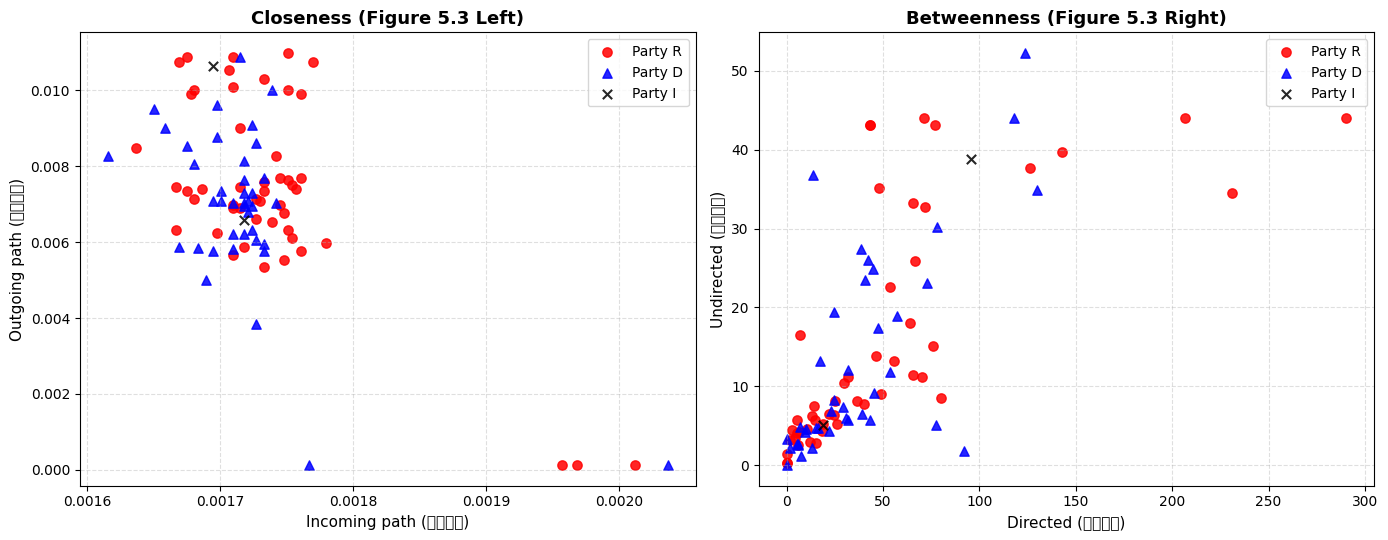


=== 原书 4-节点微型网络 PageRank 迭代收敛结果 (第 11 轮收敛) ===
Node 1: 0.2213090
Node 2: 0.4316623
Node 3: 0.2209565
Node 4: 0.1315563


In [13]:
# ------------------------------------------------------------------------------
# 5.2.4 Directed Graph and Centrality (PageRank)
# ------------------------------------------------------------------------------
# R equivalent:
#   senator$indegree <- degree(twitter.adj, mode = "in")
#   senator$outdegree <- degree(twitter.adj, mode = "out") 
#   plot(closeness(twitter.adj, mode = "in"), closeness(twitter.adj, mode = "out"))
#   plot(betweenness(twitter.adj, directed = TRUE), betweenness(twitter.adj, directed = FALSE))
#   senator$pagerank <- page.rank(twitter.adj)$vector
#   plot(twitter.adj, vertex.size = senator$pagerank * 1000)
#   PageRank iterative function with while loop

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

# 1. 计算入度与出度 (In-degree & Out-degree)
senator["indegree"] = senator["screen_name"].map(dict(G_twitter.in_degree()))
senator["outdegree"] = senator["screen_name"].map(dict(G_twitter.out_degree()))

print("=== Table 5.4: 3 Greatest Indegree (受关注最高 - 声望焦点) ===")
top_in = senator.sort_values("indegree", ascending=False)[["screen_name", "name", "party", "state", "indegree", "outdegree"]].head(3)
print(top_in.to_string(index=False))

print("\n=== Table 5.4: 3 Greatest Outdegree (关注他人最多 - 社交活跃) ===")
top_out = senator.sort_values("outdegree", ascending=False)[["screen_name", "name", "party", "state", "indegree", "outdegree"]].head(3)
print(top_out.to_string(index=False))

# 2. 计算有向紧密中心度 (Closeness: Incoming vs Outgoing)
# 原书 R igraph 采用未归一化紧密中心度: 1 / sum(dist)，不可达距离记为 n = 91
n_nodes = len(senator)
spl = dict(nx.all_pairs_shortest_path_length(G_twitter))

closeness_in = {}
closeness_out = {}
for u in G_twitter.nodes():
    # Outgoing: 从 u 出发到达其他节点的距离
    d_out = [spl[u].get(v, n_nodes) for v in G_twitter.nodes() if v != u]
    closeness_out[u] = 1.0 / sum(d_out) if sum(d_out) > 0 else 0

for v in G_twitter.nodes():
    # Incoming: 从其他节点出发到达 v 的距离
    d_in = [spl[u].get(v, n_nodes) for u in G_twitter.nodes() if u != v]
    closeness_in[v] = 1.0 / sum(d_in) if sum(d_in) > 0 else 0

senator["closeness_in"] = senator["screen_name"].map(closeness_in)
senator["closeness_out"] = senator["screen_name"].map(closeness_out)

# 3. 计算有向与无向介数中心度 (Betweenness: Directed vs Undirected)
# NetworkX normalized=False 还原原书未归一化测地线计数
senator["betweenness_dir"] = senator["screen_name"].map(
    nx.betweenness_centrality(G_twitter, normalized=False)
)
senator["betweenness_undir"] = senator["screen_name"].map(
    nx.betweenness_centrality(G_twitter.to_undirected(), normalized=False)
)

# 4. 计算 PageRank 权重
pr_dict = nx.pagerank(G_twitter, alpha=0.85)
senator["pagerank"] = senator["screen_name"].map(pr_dict)

print("\n=== Top 5 PageRank Senators (高权威核心议员) ===")
print(senator.sort_values("pagerank", ascending=False)[["name", "party", "state", "pagerank"]].head(5).to_string(index=False))

# 5. 可视化对比: Figure 5.3 (Closeness & Betweenness 对比散点图)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# 映射党派颜色与形状: R=红色圆点, D=蓝色三角, I=黑色叉号
color_map = {"R": "red", "D": "blue", "I": "black"}
marker_map = {"R": "o", "D": "^", "I": "x"}

# Panel A: Closeness (Incoming vs Outgoing)
for party in ["R", "D", "I"]:
    sub = senator[senator["party"] == party]
    axes[0].scatter(
        sub["closeness_in"], sub["closeness_out"],
        c=color_map[party], marker=marker_map[party],
        s=45, alpha=0.85, label=f"Party {party}"
    )
axes[0].set_title("Closeness (Figure 5.3 Left)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Incoming path (收敛距离)", fontsize=11)
axes[0].set_ylabel("Outgoing path (广播距离)", fontsize=11)
axes[0].legend(frameon=True)
axes[0].grid(True, linestyle="--", alpha=0.4)

# Panel B: Betweenness (Directed vs Undirected)
for party in ["R", "D", "I"]:
    sub = senator[senator["party"] == party]
    axes[1].scatter(
        sub["betweenness_dir"], sub["betweenness_undir"],
        c=color_map[party], marker=marker_map[party],
        s=45, alpha=0.85, label=f"Party {party}"
    )
axes[1].set_title("Betweenness (Figure 5.3 Right)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Directed (有向介数)", fontsize=11)
axes[1].set_ylabel("Undirected (无向介数)", fontsize=11)
axes[1].legend(frameon=True)
axes[1].grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

# 6. 原书 4-节点微型网络 PageRank 迭代算法 (Gauss-Seidel 就地更新)
nodes_toy = 4
adj_toy = np.array([
    [0, 1, 0, 1],
    [1, 0, 1, 0],
    [0, 1, 0, 0],
    [0, 1, 0, 0]
])

def PageRank_algorithm(n, A, d, pr):
    # A[i, j] = 1 表示 i -> j, 出度为行和
    deg = A.sum(axis=1)
    for j in range(n):
        pr[j] = (1 - d) / n + d * np.sum(A[:, j] * pr / deg)
    return pr

d = 0.85
pr_toy = np.full(nodes_toy, 1.0 / nodes_toy)
diff = 100.0
step = 0

while diff > 0.001:
    pr_prev = pr_toy.copy()
    pr_toy = PageRank_algorithm(nodes_toy, adj_toy, d, pr_toy)
    diff = np.max(np.abs(pr_toy - pr_prev))
    step += 1

print(f"\n=== 原书 4-节点微型网络 PageRank 迭代收敛结果 (第 {step} 轮收敛) ===")
for i, val in enumerate(pr_toy, start=1):
    print(f"Node {i}: {val:.7f}")


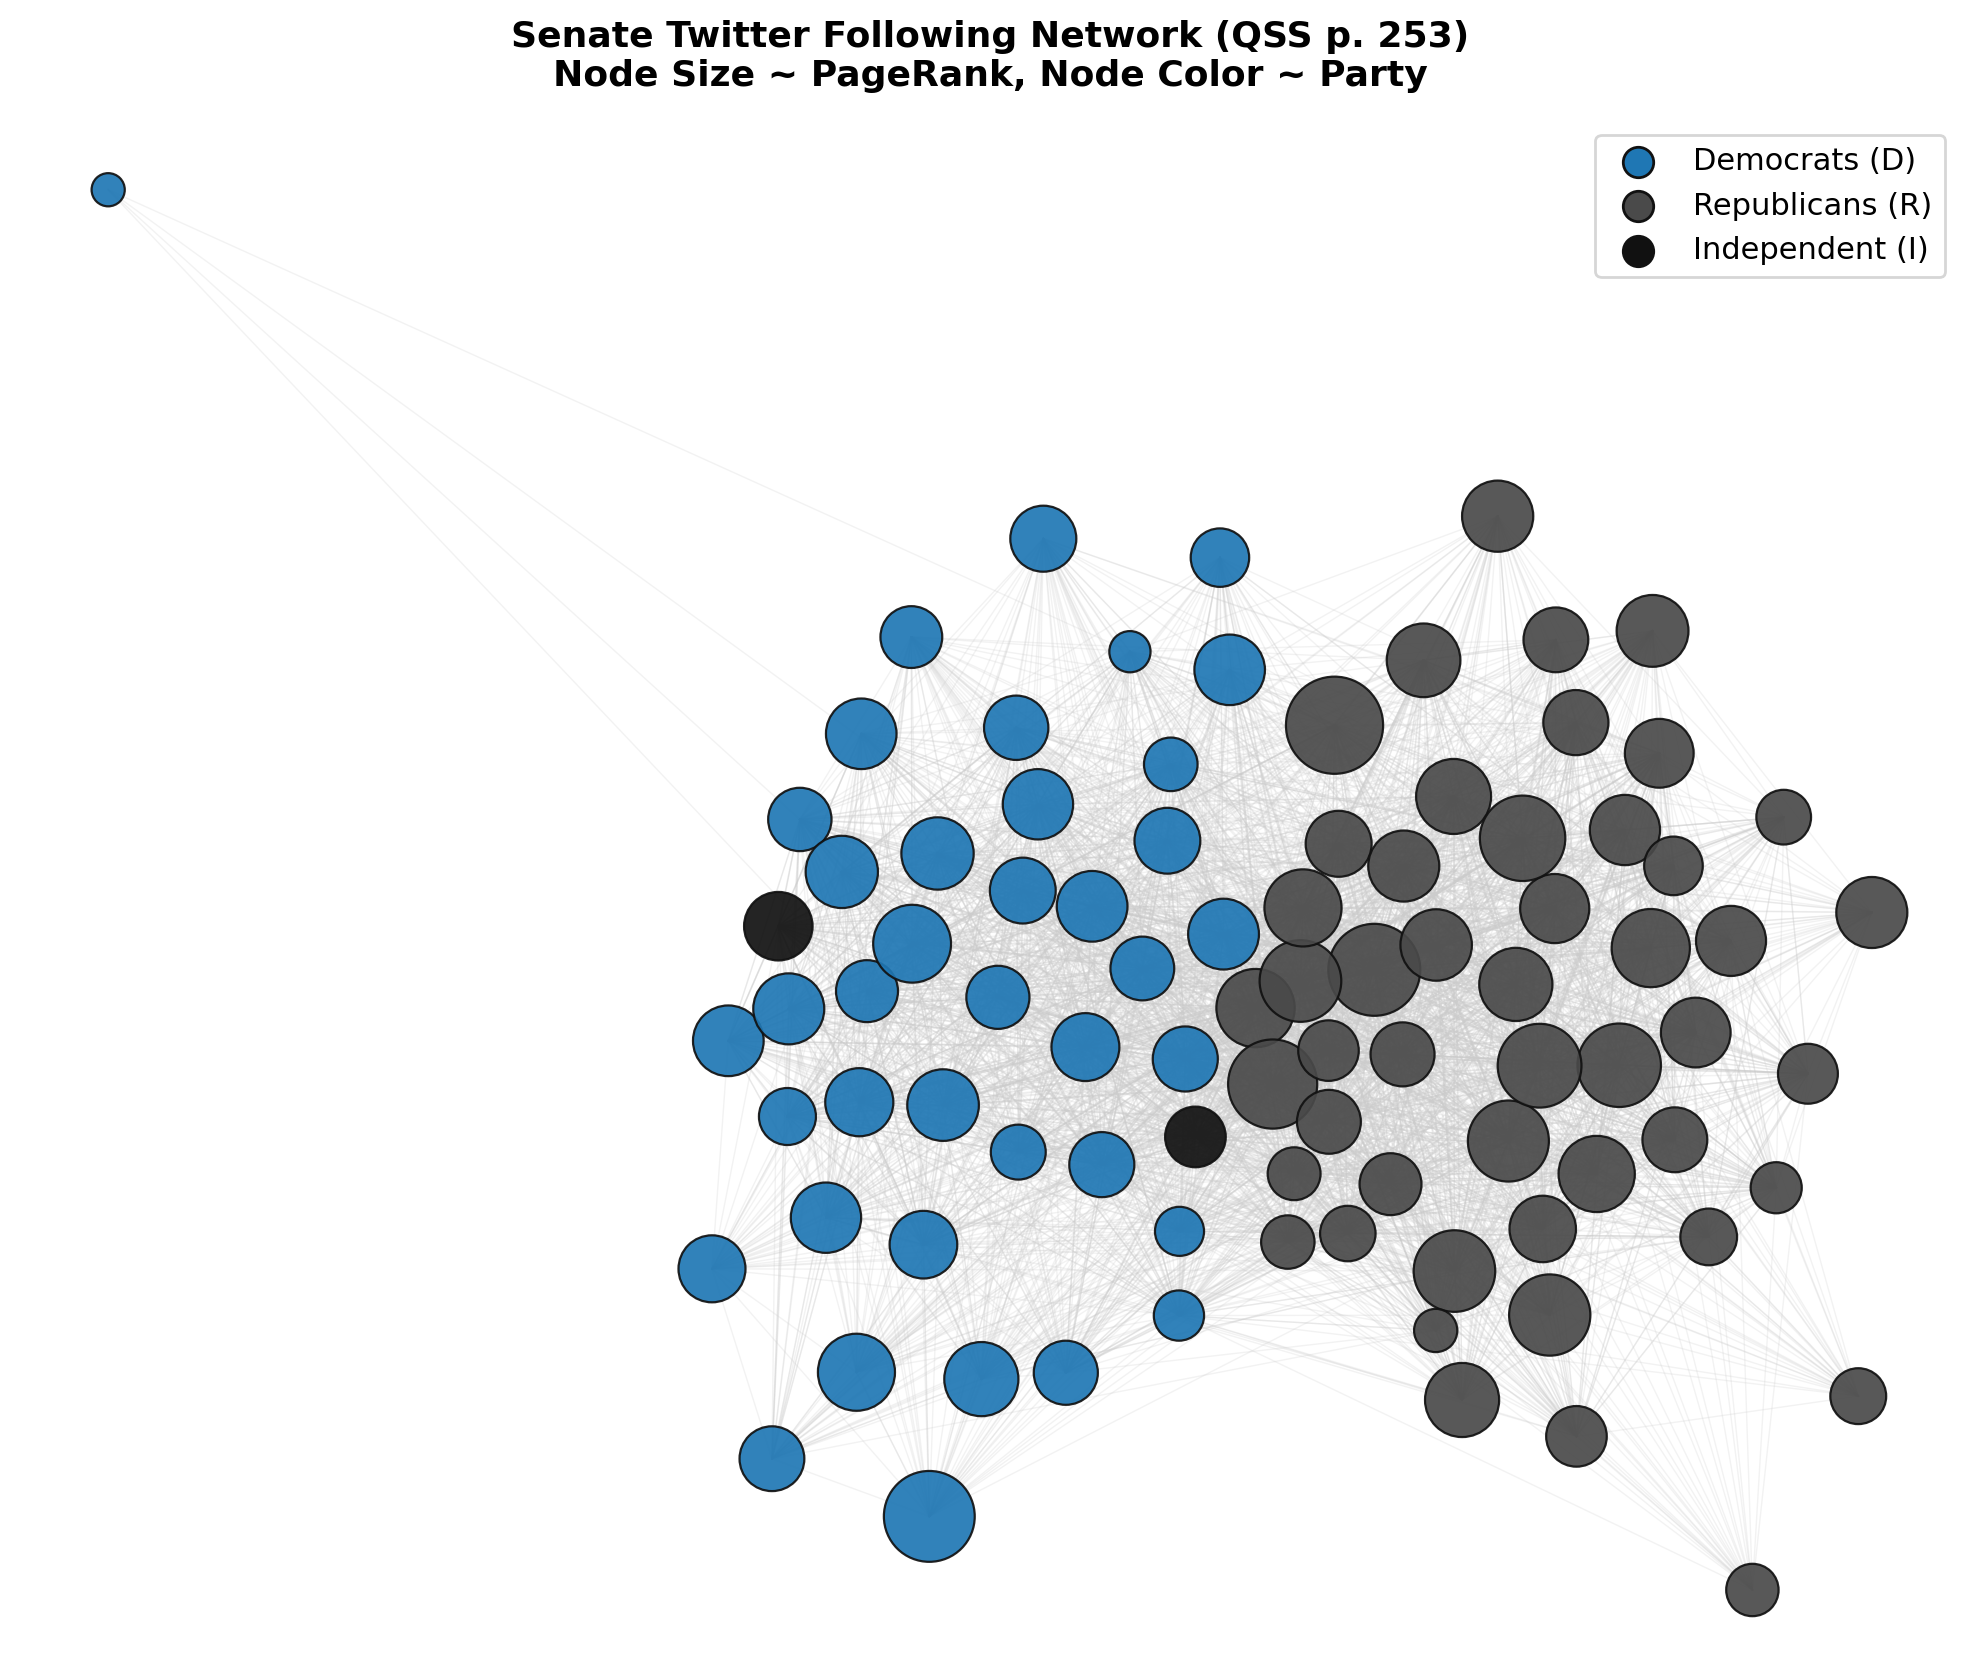

In [15]:
# ------------------------------------------------------------------------------
# 5.2.4.2 全网拓扑力导向可视化 (Figure on p. 253: Partisan Polarization Network)
# ------------------------------------------------------------------------------
# R equivalent:
#   col <- case_when(party == "R" ~ "red", party == "D" ~ "blue", TRUE ~ "black")
#   plot(net, vertex.size = V(net)$page_rank * 1000, vertex.color = col,
#        edge.arrow.size = 0.1, edge.width = 0.5)

import igraph as ig
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. 采用 Fruchterman-Reingold 弹簧力导向布局 (还原 R igraph 默认排版)
g_senate = ig.Graph.TupleList(follow[["following", "followed"]].itertuples(index=False), directed=True)
for s in senator["screen_name"]:
    if s not in g_senate.vs["name"]:
        g_senate.add_vertex(name=s)

party_map = dict(zip(senator["screen_name"], senator["party"]))
g_senate.vs["party"] = [party_map[name] for name in g_senate.vs["name"]]
pr_scores = g_senate.pagerank(damping=0.85)

# 2. 计算节点物理坐标并校准方位 (确保民主党在上、共和党在下，与原书一致)
np.random.seed(123)
layout = g_senate.layout_fruchterman_reingold(niter=500)
coords = np.array(layout.coords)

d_mask = np.array(g_senate.vs["party"]) == "D"
r_mask = np.array(g_senate.vs["party"]) == "R"
if coords[d_mask, 1].mean() < coords[r_mask, 1].mean():
    coords[:, 1] = -coords[:, 1]

coords = (coords - coords.min(axis=0)) / (coords.max(axis=0) - coords.min(axis=0))

# 3. 映射原书党派着色与 PageRank 面积
colors = [
    "#1F77B4" if p == "D" else "#4A4A4A" if p == "R" else "#111111"
    for p in g_senate.vs["party"]
]
sizes = np.array(pr_scores) * 55000

# 4. 高精度力导向网络渲染
fig, ax = plt.subplots(figsize=(10, 8.5), facecolor="white")

# 绘制 3859 条单向关注背景线
for e in g_senate.es:
    src, tgt = e.source, e.target
    ax.plot([coords[src, 0], coords[tgt, 0]], [coords[src, 1], coords[tgt, 1]],
            color="#CCCCCC", alpha=0.25, linewidth=0.5, zorder=1)

# 绘制参议员节点 (面积 = PageRank 权威值)
ax.scatter(coords[:, 0], coords[:, 1], s=sizes, c=colors,
           alpha=0.92, edgecolors="#111111", linewidths=0.8, zorder=2)

ax.scatter([], [], s=120, c="#1F77B4", edgecolors="#111111", label="Democrats (D)")
ax.scatter([], [], s=120, c="#4A4A4A", edgecolors="#111111", label="Republicans (R)")
ax.scatter([], [], s=120, c="#111111", edgecolors="#111111", label="Independent (I)")
ax.legend(frameon=True, fontsize=11, loc="upper right")

ax.set_title("Senate Twitter Following Network (QSS p. 253)\nNode Size ~ PageRank, Node Color ~ Party",
             fontsize=13, fontweight="bold", pad=12)
ax.axis("off")
plt.tight_layout()
plt.show()

两极分离空间结构：
上半部分聚集为蓝色团块（民主党），下半部分聚集为深灰团块（共和党）。算法在未被告知任何先验党派标签的前提下，仅凭关注连边拓扑即可实现无监督两党聚类分割。
大尺寸核心节点：
圆圈面积代表 PageRank。处于各自党派核心区域的大圆为建制派领袖（如 John McCain, John Cornyn, Martin Heinrich）。
顶端尖峰悬挂点：
图形正上方通过几条极细虚线悬挂的孤立小圆点为 SenBookerOfc（入度仅 4，出度为 0）。因其连边极少，在力导向算法的全网节点斥力作用下被彻底挤压至边缘顶点。


### 散点图核心认知框架 (Cognitive Deconstruction)

这两幅图是利用网络中心度揭示**参议员权力形态、信息获取策略与党派极化割裂**的核心诊断图。

---

### 一、左图：紧密中心度 (Closeness: Incoming vs. Outgoing)

```
        Outgoing Path (广播效率: 我触达全网的速度)
             ^
      0.011 -|   [全向监听型议员] (Dean Heller, David Perdue)
             |   关注全网几乎所有人 (Outdegree≈88-89)，单步直达
             |   
             |                ● ▲ (主流议员集群)
             |             ●  ▲ ▲ ●
             |            ▲  ●  ●
      0.000 -|---------------------------------------●---●---▲--> Incoming Path (权威吸收率: 全网触达我的速度)
           0.0016                                  0.0020
                                                  [纯权力黑洞型领袖] (Mitch McConnell, Bill Nelson)
                                                  绝不关注他人 (C_out≈0)，但全网都在关注他 (C_in极高)
```

#### 1. 坐标轴的物理意义
* **横轴：Incoming path（传入紧密度）**
  * 物理含义：从全网其他参议员出发，沿着有向箭头“流向”该议员的最短步数总和的倒数。
  * **越高（越偏右）**：说明他在网络中是**权威汇聚中心**，任何信息从外部流向他最快（别人都在单向跟踪他）。
* **纵轴：Outgoing path（传出紧密度）**
  * 物理含义：该议员沿着自己的关注箭头“走向”全网其他节点的最短步数总和的倒数。
  * **越高（越偏上）**：说明他是**信息索取狂人**，关注了极多议员，向全网广播或搜集全网情报极其高效。

#### 2. 两类极度分化的政治学角色
* **底部贴地极端点（$C_{\text{out}} \approx 0.00012, C_{\text{in}} \ge 0.00196$）**：
  * **代表人物**：多数党领袖 **Mitch McConnell (R-KY)**、资深民主党人 **Bill Nelson (D-FL)**、**Ben Sasse (R-NE)**。
  * **机制**：McConnell 极度高傲，Twitter 上基本不主动关注同僚（出度极低），导致他去往全网的理论距离被判定为无穷大（未归一化值贴底）；但他享有极高的党内关注度，因此 $C_{\text{in}}$ 霸占全院最右侧。这是经典的**“只输出影响力、不输入冗余噪音”的建制派权力特征**。
* **顶部密集集群（$C_{\text{out}} \ge 0.010$）**：
  * **代表人物**：**Dean Heller (R-NV)**、**David Perdue (R-GA)**、**Robert Casey (D-PA)**。
  * **机制**：出度高达 88–89（关注了参议院 97% 以上的账号），到全网绝大部分节点只需 1 步，属于**全景式情报搜集与网络外联型节点**。

---

### 二、右图：介数中心度 (Betweenness: Directed vs. Undirected)

```
        Undirected Betweenness (无向假设下的中介度)
             ^
        55 -|                ▲ (Patty Murray: 民主党党内枢纽)
            |               /
        40 -|              /  ● (Lisa Murkowski: 跨党有向咽喉)
            |             /  /
        20 -|       ● ▲  /  /
            |     ▲ ● ▲ /  /
         0 -|----▲-●---/--/------------------------●-------------> Directed Betweenness (真实单向流通下的瓶颈度)
            0        50  100                      290
```

#### 1. 坐标轴的物理意义
* **纵轴：Undirected（无向介数）**
  * 假设连边为双向电话线（忽略关注方向）。此时一个节点只要处于民主党与共和党交界处，信息即可任意双向漫游。
* **横轴：Directed（有向介数）**
  * 严格遵从单向 Twitter 箭头 $A \to B \to C$。信息不能逆箭头流动。

#### 2. 为什么大量点沿直线分布，而极少数点横向暴冲到 200–290？
* **常规节点（靠近原点）**：
  * 处于党派内部，无论是向内看还是忽略方向，它们都只是本党内部的普通节点，介数皆低于 50。
* **横向暴冲的极端中继点（$B_{\text{dir}} \ge 200$）**：
  * **代表人物**：**Lisa Murkowski (R-AK, $B_{\text{dir}} = 290.38$)**、**John Cornyn (R-TX, $B_{\text{dir}} = 230.92$)**、**Dean Heller (R-NV, $B_{\text{dir}} = 206.56$)**。
  * **政治学因果机制（单向回音室的咽喉阀门）**：
    * 参议院网络被党派撕裂为两个高度封闭的“信息孤岛”（红蓝对峙）。
    * 民主党议员极少主动关注共和党人，共和党人亦然。
    * **当且仅当**像 Murkowski 这样的温和派议员同时与两党存在交叉单向关注时，任何试图从民主党流向共和党（或反向）的信息，在严格遵循单向传递的物理规则下，**全部必须死死借道她这一两个节点**。
    * 忽略方向时（纵轴），两党边界看似有很多连线（无向介数仅 44）；但在真实有向约束下（横轴），可通行的单向管道屈指可数，导致 Murkowski 的有向控制力暴增 6 倍以上（飙升至 290.38）。

---

### 三、总结判读法则

1. **左图揭示“信息位阶”**：右上是外联枢纽，右下是特权核心（被万人瞩目却不看他人），左下是边缘议员。
2. **右图揭示“极化结构洞”**：偏离对角线极度向右突出的点，是**单向极化壁垒中极其脆弱且不可替代的跨党咽喉**。

In [14]:
import numpy as np

# 1. 拓扑邻接矩阵定义 (4 节点)
nodes = 4
adj = np.array([
    [0, 1, 0, 1],
    [1, 0, 1, 0],
    [0, 1, 0, 0],
    [0, 1, 0, 0]
])

# 2. 定义单步更新函数
def PageRank(n, A, d, pr):
    # deg: 各节点出度 (行和)
    deg = A.sum(axis=1)
    for j in range(n):
        # A[:, j] 提取所有指向 j 的节点
        pr[j] = (1 - d) / n + d * np.sum(A[:, j] * pr / deg)
    return pr

# 3. while 循环迭代求解
d = 0.85
pr = np.full(nodes, 1.0 / nodes) # [0.25, 0.25, 0.25, 0.25]
diff = 100.0
step = 0

while diff > 0.001:
    pr_pre = pr.copy()
    pr = PageRank(nodes, adj, d, pr)
    diff = np.max(np.abs(pr - pr_pre))
    step += 1

print(f"收敛步数: {step}")
for i, val in enumerate(pr, 1):
    print(f"Node {i}: {val:.7f}")

收敛步数: 11
Node 1: 0.2213090
Node 2: 0.4316623
Node 3: 0.2209565
Node 4: 0.1315563


# 5.3 Spatial Data (空间数据)
> **原书对应**：Section 5.3 | PDF 第 263–278 页  
> **核心经验问题**：空间维度的因果识别与实证可视化。从 John Snow 1854 年伦敦霍乱水井点模式分析（流行病学因果推断发轫），到美国县级大选红蓝色阶地图（Choropleth Maps），以及沃尔玛横跨 40 年的空间扩散时空演进。


## 5.3.1 Spatial Data & Mapping Basics (1854 London Cholera)
> **原书坐标**：Section 5.3.1 | PDF 第 264–270 页 | Figure 5.8, 5.9

#### 1. 因果与量化方法论逻辑 (Methodological Rationale)
* **空间点模式与自然实验雏形**：John Snow 通过标记霍乱死亡家庭与公共水井的相对空间距离，证伪了空气瘴气说（Miasma Theory），建立了水传播疾病的因果机制。
* **投影与坐标参考系（CRS）**：经纬度（WGS84）向平面地图的投影投射。


In [ ]:
# ------------------------------------------------------------------------------
# 5.3.1 Spatial Data in Python & Mapping Basics (Cholera Outbreak / US Maps)
# ------------------------------------------------------------------------------
# R equivalent:
#   map("state")
#   points for state capitals and CA cities

# TODO:
# --- 5.3.1.1 Spatial Coordinate Mapping and Base Maps ---
# 1. Plot US state basemap using geopandas or cartopy / matplotlib
# 2. Plot coordinate points (longitude, latitude) of capitals and major cities

# --- 5.3.1.2 1854 London Cholera Outbreak Point Pattern Analysis ---
# 3. Plot deaths relative to Broad Street pump



## 5.3.2 United States Presidential Elections (Choropleth Maps)
> **原书坐标**：Section 5.3.2 | PDF 第 270–274 页 | Figure 5.10, 5.11

#### 1. 因果与量化方法论逻辑 (Methodological Rationale)
* **生态学谬误与地图色阶偏差**：
  * 简单二元胜负图（Winner-take-all Red/Blue）会夸大地广人稀保守选区的影响力。
  * **紫色连续色阶图（Purple Shades）**：以得票率连续变量加权着色，消除人造行政边界带来的极端极化错觉，展现真实的政治温和中间地带。


In [ ]:
# ------------------------------------------------------------------------------
# 5.3.2 United States Presidential Elections (Choropleth Maps)
# ------------------------------------------------------------------------------
# R equivalent:
#   pres08 <- read_csv("pres08.csv")
#   merge with county/state map polygons
#   shading red (McCain) / blue (Obama) / purple shades

# TODO:
# --- 5.3.2.1 Ingest Election Returns & Geographic Polygons ---
# 1. Load pres08.csv and calculate Democratic vote share
# 2. Join vote share to US county/state polygon GeoDataFrame

# --- 5.3.2.2 Plot Categorical & Continuous Choropleth Maps ---
# 3. Plot Choropleth maps (binary red/blue winner fills and continuous purple gradient)



## 5.3.3 Expansion of Walmart & Spatial-Temporal Animation
> **原书坐标**：Section 5.3.3 | PDF 第 274–278 页 | Figure 5.12, 5.13

#### 1. 因果与量化方法论逻辑 (Methodological Rationale)
* **空间扩散过程（Spatial Diffusion Process）**：连锁企业扩张并非随机离散点，而是遵循以配送中心（Distribution Centers）为同心圆核心的空间辐射。
* **时空动态演进（Spatial-Temporal Animation）**：通过时间轴动态累积展示门店开业历程，验证企业物流成本最小化假说。


In [ ]:
# ------------------------------------------------------------------------------
# 5.3.3 Expansion of Walmart & Spatial Animation
# ------------------------------------------------------------------------------
# R equivalent:
#   walmart <- read_csv("walmart.csv")
#   spatial plot of store locations
#   animated store openings over years (1962 - 2006)

# TODO:
# --- 5.3.3.1 Ingest Longitudinal Store Location Records ---
# 1. Load walmart.csv and parse opendate
# 2. Plot point distribution of Walmart stores and distribution centers across the US

# --- 5.3.3.2 Spatial-Temporal Cumulative Animation ---
# 3. Create temporal cumulative animation of store openings (matplotlib.animation / FuncAnimation)